# Uji Validitas & Reliabilitas Kuesioner TIA


In [1]:
import os, re, glob
import pandas as pd, numpy as np
from scipy import stats

NAMA_FILE = "HasilSurveyTIA.xlsx"
NAMA_OUTPUT = "hasil_uji_validitas_reliabilitas.xlsx"
KELAS = "3 TI A"

if not os.path.exists(NAMA_FILE):
    kandidat = [f for f in glob.glob("*.xlsx") if f != NAMA_OUTPUT]
    if not kandidat:
        raise FileNotFoundError("Tidak ada file .xlsx di root Colab. Upload dulu HasilSurveyTIA.xlsx.")
    NAMA_FILE = kandidat[0]
print("File terbaca:", NAMA_FILE)

File terbaca: HasilSurveyTIA.xlsx


## 1. Membaca data & memilih butir pernyataan


In [2]:
df = pd.read_excel(NAMA_FILE)
if KELAS is not None:
    df = df[df["Kelas"] == KELAS].reset_index(drop=True)
    print("Kelas dianalisis :", KELAS)

pola = re.compile(r"^\s*(.*?)\s*\[(.*)\]\s*$", re.S)
kolom_butir = [k for k in df.columns if pola.match(str(k))]
kolom_lain = [k for k in df.columns if k not in kolom_butir]

butir = df[kolom_butir]
print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))
print("\nKolom yang tidak diuji:")
for k in kolom_lain:
    print(" -", k)

Kelas dianalisis : 3 TI A
Jumlah responden : 39
Jumlah butir     : 29
Data kosong      : 0

Kolom yang tidak diuji:
 - Timestamp
 - Score
 - Kelas
 - Jenis Kelamin
 - Jumlah Platform AI yang rutin digunakan untuk membatu menyelesaikan tugas atau projek
 - Jumlah Platform AI yang berlangganan secara premium (bukan free)
 - Durasi (jam) rata-rata penggunaan gadget perhari, untuk , kebutuhan harian sampai dengan hiburan 


In [3]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))

print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
1,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
2,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
3,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
4,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


## 2. Pengelompokan butir per dimensi


In [4]:
RENAME = {"Rsspon emosional": "Respon emosional"}

dimensi = {}
pernyataan = []
for kolom in butir.columns:
    m = pola.match(kolom)
    nama = m.group(1).strip().rstrip(". ")
    nama = RENAME.get(nama, nama)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")
    for i, kolom in enumerate(daftar, 1):
        teks = pola.match(kolom).group(2).strip()
        pernyataan.append({"Dimensi": nama, "Butir": f"B{i}", "Pernyataan": teks})

tabel_pernyataan = pd.DataFrame(pernyataan)

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


## 3. Uji validitas (korelasi Pearson butir–skor total dimensi)


In [5]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
            "Keterangan (corrected r)": "Valid" if r_koreksi > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan,Keterangan (corrected r)
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.277,0.0006,Valid,Tidak valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.379,0.0000,Valid,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.397,0.0000,Valid,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.126,0.0008,Valid,Tidak valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.139,0.0036,Valid,Tidak valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.228,0.0004,Valid,Tidak valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.377,0.0000,Valid,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.213,0.0014,Valid,Tidak valid


## 4. Uji reliabilitas (Cronbach's alpha per dimensi)


In [6]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})

    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({"Dimensi": nama, "Butir": f"B{i}",
                                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik,4,0.863,Baik
4,Respon emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.312


## 5. Analisis deskriptif per dimensi


,Dimensi,Jumlah butir,Rata-rata skor total,Rata-rata per butir,SD,Min,Maks,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,7,27.28,3.90,3.02,19,34,-0.42,1.61
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,21.92,3.13,3.74,15,30,0.25,-0.75
2,Kebiasaan penggunaan teknologi digital,6,16.69,2.78,3.72,8,24,-0.25,-0.21
3,Prokrastinasi akademik,4,11.05,2.76,4.06,4,19,0.24,-0.55
4,Respon emosional,5,19.38,3.88,3.32,7,25,-1.52,3.95


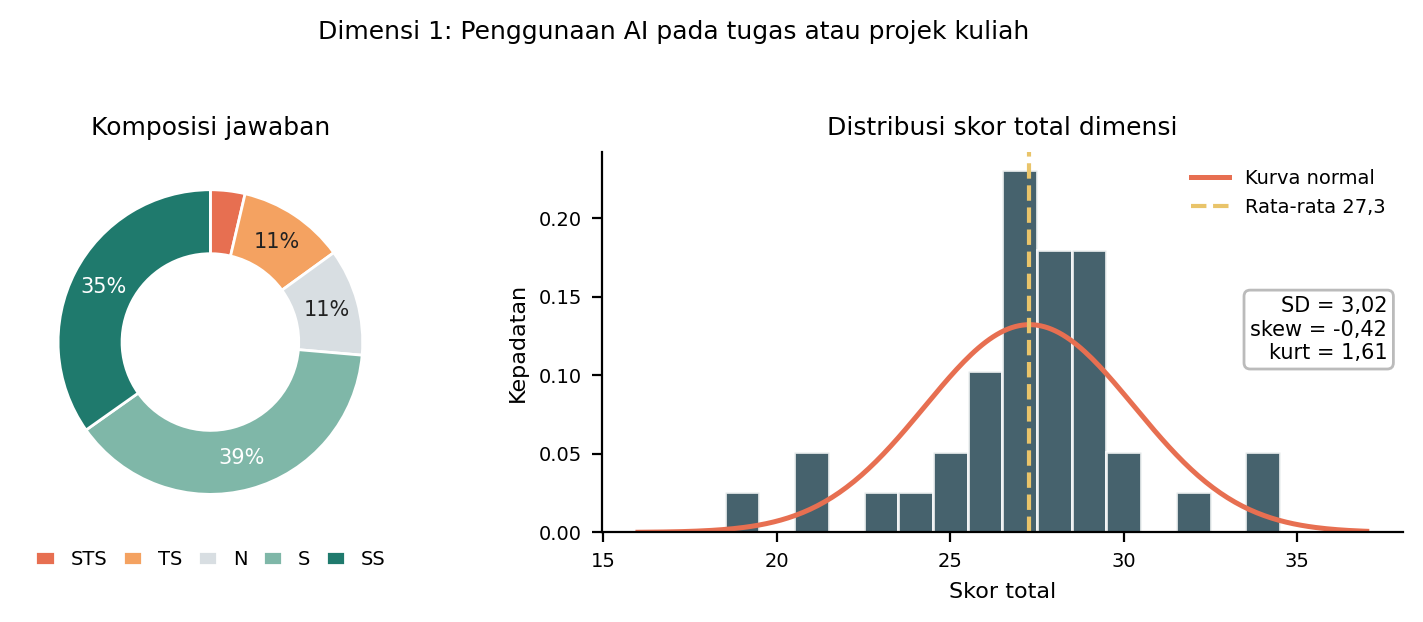

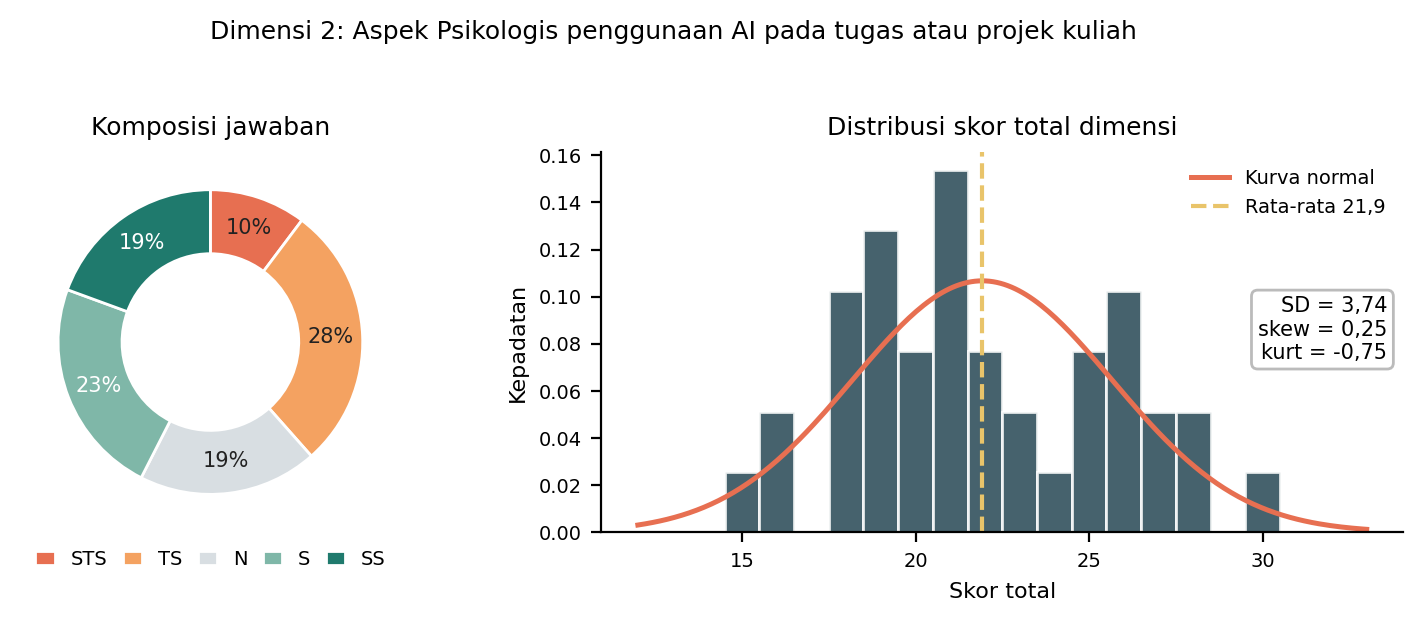

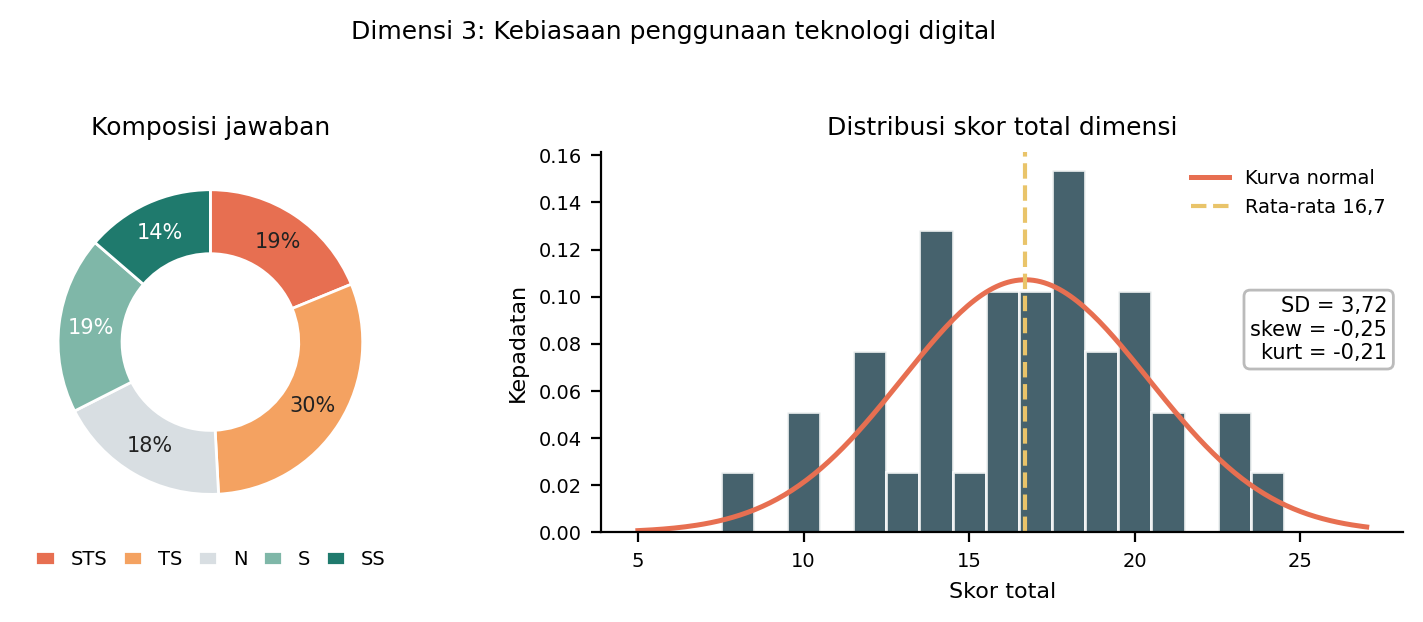

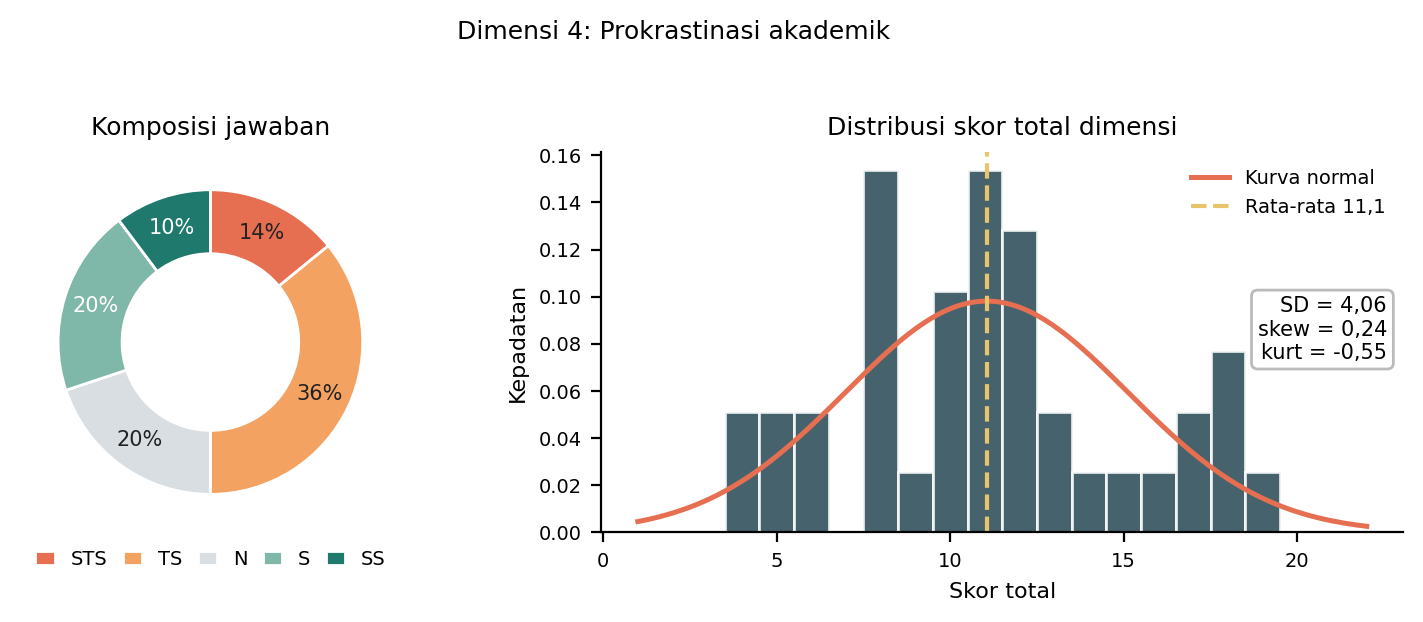

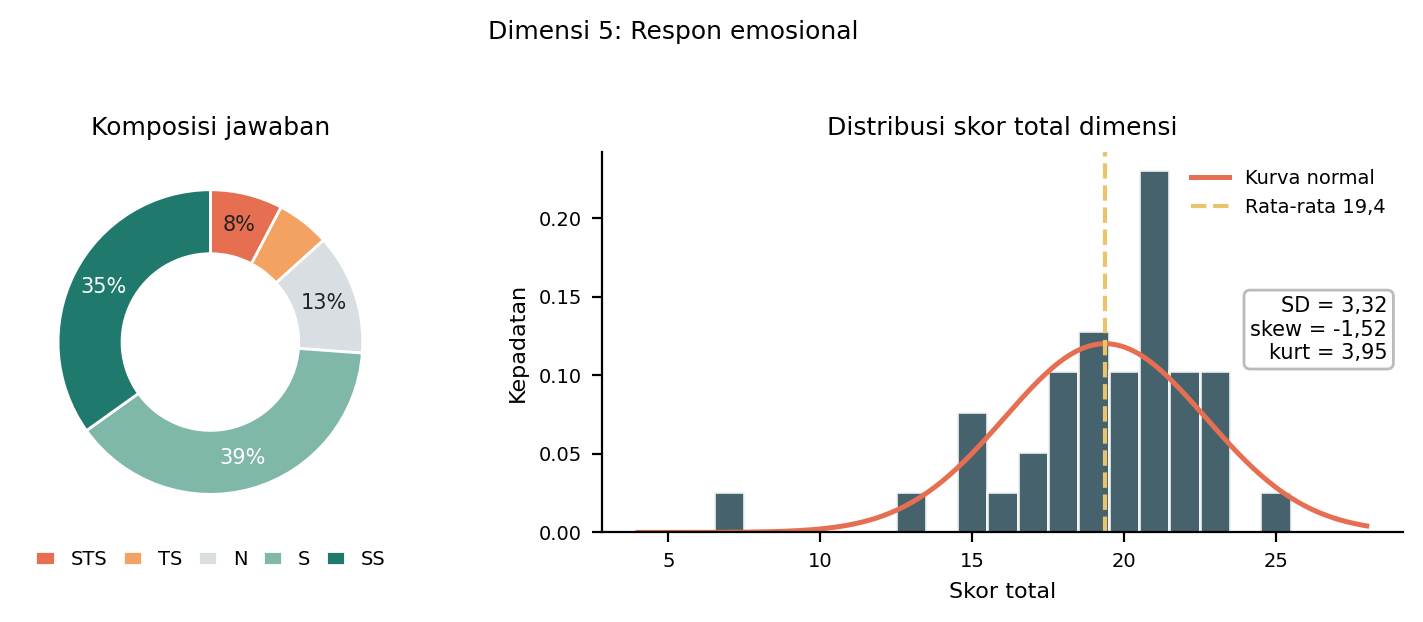

In [7]:
import matplotlib.pyplot as plt

hasil_desk = []
for nama, daftar in dimensi.items():
    total = num[daftar].sum(axis=1)
    hasil_desk.append({
        "Dimensi": nama, "Jumlah butir": len(daftar),
        "Rata-rata skor total": round(total.mean(), 2),
        "Rata-rata per butir": round(num[daftar].values.mean(), 2),
        "SD": round(total.std(ddof=1), 2),
        "Min": int(total.min()), "Maks": int(total.max()),
        "Skewness": round(stats.skew(total, bias=False), 2),
        "Kurtosis": round(stats.kurtosis(total, bias=False), 2),
    })
tabel_deskriptif = pd.DataFrame(hasil_desk)
display(tabel_deskriptif)

import os
os.makedirs("grafik", exist_ok=True)

label = ["STS", "TS", "N", "S", "SS"]
warna = ["#E76F51", "#F4A261", "#D8DEE2", "#7FB7A8", "#1F7A6D"]

for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    k = len(daftar)
    total = num[daftar].sum(axis=1)
    komposisi = [(num[daftar].values == v).mean() * 100 for v in range(1, 6)]

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.0), dpi=200,
                                 gridspec_kw={"width_ratios": [1, 1.5]})


    # Kiri: donut komposisi jawaban
    w, _ = a1.pie(komposisi, colors=warna, startangle=90, counterclock=False,
                  wedgeprops=dict(width=0.42, edgecolor="white"))
    for wi, p in zip(w, komposisi):
        if p >= 6:
            ang = np.deg2rad((wi.theta1 + wi.theta2) / 2)
            a1.text(0.79 * np.cos(ang), 0.79 * np.sin(ang), f"{p:.0f}%", ha="center", va="center",
                    fontsize=7.5, color="white" if wi.get_facecolor()[0] < 0.6 else "#222")
    a1.legend(w, label, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=5,
              frameon=False, fontsize=7, handlelength=1, columnspacing=0.8)
    a1.set_title("Komposisi jawaban", fontsize=9)


    # Kanan: histogram skor total + kurva normal
    bins = np.arange(k - 0.5, 5 * k + 1.5, 1) if k <= 5 else np.arange(total.min() - 0.5, total.max() + 1.5, 1)
    a2.hist(total, bins=bins, color="#264653", alpha=0.85, density=True, edgecolor="white")
    xs = np.linspace(total.min() - 3, total.max() + 3, 200)
    a2.plot(xs, stats.norm.pdf(xs, total.mean(), total.std(ddof=1)), color="#E76F51", lw=1.8, label="Kurva normal")
    a2.axvline(total.mean(), color="#E9C46A", lw=1.5, ls="--", label=f"Rata-rata {total.mean():.1f}".replace(".", ","))
    a2.set_title("Distribusi skor total dimensi", fontsize=9)
    a2.set_xlabel("Skor total", fontsize=8)
    a2.set_ylabel("Kepadatan", fontsize=8)
    a2.tick_params(labelsize=7)
    a2.spines[["top", "right"]].set_visible(False)
    a2.legend(fontsize=7, frameon=False)
    a2.text(0.98, 0.62,
            f"SD = {total.std(ddof=1):.2f}\nskew = {stats.skew(total, bias=False):.2f}\nkurt = {stats.kurtosis(total, bias=False):.2f}".replace(".", ","),
            transform=a2.transAxes, ha="right", va="top", fontsize=7.5,
            bbox=dict(boxstyle="round", fc="white", ec="#bbb"))

    fig.suptitle(f"Dimensi {d}: {nama}", fontsize=9, y=1.02)
    plt.tight_layout()
    plt.savefig(f"grafik/dimensi{d}.png", bbox_inches="tight")
    plt.show()

## 6. Ekspor hasil ke Excel

In [8]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter(NAMA_OUTPUT) as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_pernyataan.to_excel(w, sheet_name="Daftar Butir", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif", index=False)

try:
    from google.colab import files
    files.download(NAMA_OUTPUT)
    import shutil
    shutil.make_archive("grafik_dimensi", "zip", "grafik")
    files.download("grafik_dimensi.zip")
except ImportError:
    print("Bukan di Colab, file tersimpan sebagai:", NAMA_OUTPUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>